# 01 - Olist dataset discovery (EDA)

**Purpose.** Establish what the nine raw Olist files contain *before* modelling them: keys and grain, referential integrity, join fan-out, nulls and anomalies, and the distributions that matter. Every section ends with a finding, and the last section turns those findings into decisions for the star schema (`sql/`, `docs/data/DATA_MODEL.md`).

**Conventions**
- Raw files are only *read* (through DuckDB views); nothing is cleaned, re-cased or dropped here. Anything odd is documented, not silently removed.
- Zip-code prefixes are forced to `VARCHAR` so leading zeros survive.
- Wording on relationships is associational ("late delivery is associated with lower review scores"), not causal.


In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if float(v).is_integer() else f"{v:,.2f}")

# Works whether the notebook is run from the repo root or from notebooks/
DATA = Path.cwd().parent / "data" if Path.cwd().name == "notebooks" else Path.cwd() / "data"

SOURCES = {
    "orders": "olist_orders_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "translation": "product_category_name_translation.csv",
}
ZIP_TYPES = {
    "customers": "{'customer_zip_code_prefix': 'VARCHAR'}",
    "sellers": "{'seller_zip_code_prefix': 'VARCHAR'}",
}

con = duckdb.connect()
for name, file in SOURCES.items():
    types = f", types={ZIP_TYPES[name]}" if name in ZIP_TYPES else ""
    con.execute(
        f"create or replace view {name} as "
        f"select * from read_csv_auto('{(DATA / file).as_posix()}', header=true{types})"
    )
con.execute(
    "create or replace view geo as "
    f"select * from read_parquet('{(DATA / 'olist_geolocation_dataset.parquet').as_posix()}')"
)
TABLES = [*SOURCES, "geo"]


def q(sql: str) -> pd.DataFrame:
    return con.sql(sql).df()


# Chart styling: validated blue/orange pair, recessive grid, thin marks, no top/right spines
SURFACE, TEXT, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": TEXT,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False,
})
print("data dir:", DATA)

data dir: C:\Users\Student\GCP\data


## 1. Inventory
Row counts, column types and null percentages for all nine files.

In [2]:
counts = pd.DataFrame(
    [(t, con.sql(f"select count(*) from {t}").fetchone()[0], len(q(f"describe {t}"))) for t in TABLES],
    columns=["table", "rows", "columns"],
)
display(counts)

prof = pd.concat([q(f"summarize {t}").assign(table=t) for t in TABLES], ignore_index=True)
prof["null_percentage"] = prof["null_percentage"].astype(float)
prof = prof[["table", "column_name", "column_type", "null_percentage"]]
display(prof)

,table,rows,columns
0,orders,99441,8
1,customers,99441,5
2,items,112650,7
3,payments,103886,5
4,reviews,99224,7
5,products,32951,9
6,sellers,3095,4
7,translation,71,2
8,geo,1000163,5


,table,column_name,column_type,null_percentage
0,orders,order_id,VARCHAR,0
1,orders,customer_id,VARCHAR,0
2,orders,order_status,VARCHAR,0
3,orders,order_purchase_timestamp,TIMESTAMP,0
4,orders,order_approved_at,TIMESTAMP,0.16
5,orders,order_delivered_carrier_date,TIMESTAMP,1.79
6,orders,order_delivered_customer_date,TIMESTAMP,2.98
7,orders,order_estimated_delivery_date,TIMESTAMP,0
8,customers,customer_id,VARCHAR,0
9,customers,customer_unique_id,VARCHAR,0


In [3]:
print("Columns with nulls:")
display(prof[prof.null_percentage > 0].sort_values("null_percentage", ascending=False))
print("translation columns:", q("describe translation").column_name.tolist(), "(BOM handled if the first name is clean)")

Columns with nulls:


,table,column_name,column_type,null_percentage
28,reviews,review_comment_title,VARCHAR,88.34
29,reviews,review_comment_message,VARCHAR,58.70
6,orders,order_delivered_customer_date,TIMESTAMP,2.98
34,products,product_name_lenght,BIGINT,1.85
33,products,product_category_name,VARCHAR,1.85
35,products,product_description_lenght,BIGINT,1.85
36,products,product_photos_qty,BIGINT,1.85
5,orders,order_delivered_carrier_date,TIMESTAMP,1.79
4,orders,order_approved_at,TIMESTAMP,0.16
37,products,product_weight_g,BIGINT,0.01


translation columns: ['product_category_name', 'product_category_name_english'] (BOM handled if the first name is clean)


**Finding - inventory.** Nine files: orders 99,441 rows, customers 99,441, order items 112,650, payments 103,886, reviews 99,224, products 32,951, sellers 3,095, category translation 71, geolocation 1,000,163. The only material nulls are review comment title/message (88.3% / 58.7%), order approval/delivery timestamps (0.2-3.0%) and products (1.85% = 610 products with no category, photo count or name/description length; 2 with no weight or dimensions). The source misspells `product_name_lenght` and `product_description_lenght`; staging should fix the names. The translation file's BOM is handled (first column name reads clean).

## 2. Keys and grain
Which column combinations are really unique? The grain of each table decides the grain of its fact.

In [4]:
KEYS = [
    ("orders", "order_id"), ("customers", "customer_id"),
    ("items", "order_id, order_item_id"), ("payments", "order_id, payment_sequential"),
    ("reviews", "review_id"), ("reviews", "review_id, order_id"),
    ("products", "product_id"), ("sellers", "seller_id"),
    ("translation", "product_category_name"), ("geo", "geolocation_zip_code_prefix"),
]
out = []
for t, k in KEYS:
    n, d = con.sql(f"select count(*), count(distinct ({k})) from {t}").fetchone()
    out.append((t, k, n, d, n == d))
display(pd.DataFrame(out, columns=["table", "candidate_key", "rows", "distinct_keys", "is_unique"]))

,table,candidate_key,rows,distinct_keys,is_unique
0,orders,order_id,99441,99441,True
1,customers,customer_id,99441,99441,True
2,items,"order_id, order_item_id",112650,112650,True
3,payments,"order_id, payment_sequential",103886,103886,True
4,reviews,review_id,99224,98410,False
5,reviews,"review_id, order_id",99224,99224,True
6,products,product_id,32951,32951,True
7,sellers,seller_id,3095,3095,True
8,translation,product_category_name,71,71,True
9,geo,geolocation_zip_code_prefix,1000163,19015,False


In [5]:
print("customer_id is per-order; customer_unique_id is the real customer:")
display(q("select count(*) customer_ids, count(distinct customer_unique_id) unique_customers from customers"))
print("Orders per unique customer:")
display(q("""
    select orders_per_customer, count(*) customers
    from (select c.customer_unique_id, count(*) orders_per_customer
          from orders o join customers c using (customer_id) group by 1)
    group by 1 order by 1"""))
print("Unique customers whose zip prefix or state changes between orders:")
display(q("""
    select count(*) customers_with_changing_location from (
        select customer_unique_id from customers group by 1
        having count(distinct customer_zip_code_prefix) > 1 or count(distinct customer_state) > 1)"""))

print("Reviews:")
display(q("""
    select count(*) review_rows, count(distinct review_id) distinct_review_ids,
           count(distinct order_id) orders_with_review,
           (select count(*) from (select review_id from reviews group by 1
                                  having count(distinct order_id) > 1)) review_ids_on_multiple_orders
    from reviews"""))
display(q("""
    select reviews_per_order, count(*) orders
    from (select order_id, count(*) reviews_per_order from reviews group by 1)
    group by 1 order by 1"""))
print("Items / payments per order:")
display(q("""
    select (select max(order_item_id) from items) max_items_per_order,
           (select count(*) from items where order_item_id > 1) rows_in_multi_item_orders,
           (select max(c) from (select count(*) c from payments group by order_id)) max_payments_per_order,
           (select count(*) from (select order_id from payments group by 1 having count(*) > 1)) orders_with_multiple_payments,
           (select count(*) from (select order_id from items group by 1 having count(distinct seller_id) > 1)) multi_seller_orders"""))

customer_id is per-order; customer_unique_id is the real customer:


,customer_ids,unique_customers
0,99441,96096


Orders per unique customer:


,orders_per_customer,customers
0,1,93099
1,2,2745
2,3,203
3,4,30
4,5,8
5,6,6
6,7,3
7,9,1
8,17,1


Unique customers whose zip prefix or state changes between orders:


...

Reviews:


,review_rows,distinct_review_ids,orders_with_review,review_ids_on_multiple_orders
0,99224,98410,98673,789


,reviews_per_order,orders
0,1,98126
1,2,543
2,3,4


Items / payments per order:


,max_items_per_order,rows_in_multi_item_orders,max_payments_per_order,orders_with_multiple_payments,multi_seller_orders
0,21,13984,29,2961,1278


**Finding - keys and grain.**
- Unique as expected: `orders.order_id`, `customers.customer_id`, items on (`order_id`, `order_item_id`), payments on (`order_id`, `payment_sequential`), `products.product_id`, `sellers.seller_id`, the translation key.
- **Reviews are not unique on `review_id`** (99,224 rows, 98,410 ids; 789 ids appear on more than one order). (`review_id`, `order_id`) is unique, and 547 orders have two or three reviews.
- **`customer_id` is per order, not per person**: 99,441 ids map to 96,096 real customers (`customer_unique_id`); 2,997 customers (3.1%) ordered more than once, and 250 customers appear with a different zip prefix or state across orders.
- Orders are multi-line: 13,984 item rows are second-or-later items, 1,278 orders span more than one seller, and 2,961 orders have several payments (up to 29).
- `geolocation` has no key: 1,000,163 points for 19,015 zip prefixes.

## 3. Referential integrity
Orphans in both directions: children pointing at a missing parent, and parents with no children.

In [6]:
CHILD_TO_PARENT = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("items", "order_id", "orders", "order_id"),
    ("items", "product_id", "products", "product_id"),
    ("items", "seller_id", "sellers", "seller_id"),
    ("payments", "order_id", "orders", "order_id"),
    ("reviews", "order_id", "orders", "order_id"),
]
PARENT_WITHOUT_CHILD = [
    ("customers", "customer_id", "orders"), ("orders", "order_id", "items"),
    ("orders", "order_id", "payments"), ("orders", "order_id", "reviews"),
    ("products", "product_id", "items"), ("sellers", "seller_id", "items"),
]
rows = []
for c, ck, p, pk in CHILD_TO_PARENT:
    n = con.sql(f"select count(*) from {c} where {ck} not in (select {pk} from {p})").fetchone()[0]
    rows.append((f"{c}.{ck}", f"{p}.{pk}", "orphan child rows", n))
for p, pk, c in PARENT_WITHOUT_CHILD:
    n = con.sql(f"select count(*) from {p} where {pk} not in (select {pk} from {c})").fetchone()[0]
    rows.append((f"{p}.{pk}", f"{c}.{pk}", "parents with no child", n))
display(pd.DataFrame(rows, columns=["column", "references", "check", "count"]))

print("Orders without any item, by status:")
display(q("""select order_status, count(*) orders from orders
             where order_id not in (select order_id from items) group by 1 order by 2 desc"""))

,column,references,check,count
0,orders.customer_id,customers.customer_id,orphan child rows,0
1,items.order_id,orders.order_id,orphan child rows,0
2,items.product_id,products.product_id,orphan child rows,0
3,items.seller_id,sellers.seller_id,orphan child rows,0
4,payments.order_id,orders.order_id,orphan child rows,0
5,reviews.order_id,orders.order_id,orphan child rows,0
6,customers.customer_id,orders.customer_id,parents with no child,0
7,orders.order_id,items.order_id,parents with no child,775
8,orders.order_id,payments.order_id,parents with no child,1
9,orders.order_id,reviews.order_id,parents with no child,768


Orders without any item, by status:


,order_status,orders
0,unavailable,603
1,canceled,164
2,created,5
3,invoiced,2
4,shipped,1


**Finding - referential integrity.** There are **no orphan children** anywhere (every item, payment and review points at a real order; every order at a customer; every item at a product and seller). Parents without children: **775 orders have no items** (603 `unavailable`, 164 `canceled`, 5 `created`, 2 `invoiced`, 1 `shipped`), 1 order has no payment and 768 have no review. Every product and seller was sold at least once. So `orders` is the complete order set and the order-level fact must keep item-less orders.

## 4. Fan-out demonstration
Items, payments and reviews all hang off `order_id` at *different* grains. Joining them side by side repeats each item once per payment and once per review, so any item-level measure is over-counted. Left joins are used so only fan-out (not row loss) is measured.

In [7]:
true_price = con.sql("select sum(price) from items").fetchone()[0]
base = "from orders o left join items i using (order_id)"
variants = {
    "orders": "select count(*), null::double from orders",
    "+ items": f"select count(*), sum(i.price) {base}",
    "+ items + payments": f"select count(*), sum(i.price) {base} left join payments p using (order_id)",
    "+ items + payments + reviews": (
        f"select count(*), sum(i.price) {base} left join payments p using (order_id) "
        "left join reviews r using (order_id)"
    ),
}
rows = []
for label, sql in variants.items():
    n, s = con.sql(sql).fetchone()
    rows.append((label, n, s, None if s is None else s / true_price - 1))
fan = pd.DataFrame(rows, columns=["join", "rows", "sum_item_price", "overstatement_vs_true"])
display(fan.style.format({"rows": "{:,.0f}", "sum_item_price": "{:,.2f}", "overstatement_vs_true": "{:.2%}"}, na_rep="-"))
print(f"True sum of item price: {true_price:,.2f}")

,join,rows,sum_item_price,overstatement_vs_true
0,orders,"99,441",-,-
1,+ items,"113,425","13,591,643.70",0.00%
2,+ items + payments,"118,434","14,209,250.31",4.54%
3,+ items + payments + reviews,"119,143","14,273,699.65",5.02%


True sum of item price: 13,591,643.70


In [8]:
# Correct pattern: bring every child to the order grain first, then join one-to-one.
safe = q("""
    with i as (select order_id, count(*) n_items, sum(price) price, sum(freight_value) freight from items group by 1),
         p as (select order_id, count(*) n_payments, sum(payment_value) paid from payments group by 1),
         r as (select order_id, count(*) n_reviews, avg(review_score) avg_score from reviews group by 1)
    select count(*) n_rows, sum(price) sum_item_price from orders o
    left join i using (order_id) left join p using (order_id) left join r using (order_id)""")
display(safe)
assert safe.n_rows[0] == con.sql("select count(*) from orders").fetchone()[0]
assert abs(safe.sum_item_price[0] - true_price) < 0.01
print("Pre-aggregating each child to the order grain keeps one row per order and the exact item total.")

,n_rows,sum_item_price
0,99441,"13,591,643.70"


Pre-aggregating each child to the order grain keeps one row per order and the exact item total.


**Finding - fan-out.** Joining the order-grain table to items and payments side by side raises the row count from 113,425 to 118,434 and **overstates item revenue by 4.54%** (5.02% once reviews are joined, 119,143 rows) against the true 13,591,643.70. Pre-aggregating items, payments and reviews to the order grain first returns exactly 99,441 rows and the exact total (asserted above). Rule for the model: facts are never joined to each other directly; they meet through shared dimensions, or are aggregated to a common grain first.

## 5. Nulls and anomalies

In [9]:
print("Missing timestamps by order status:")
display(q("""
    select order_status, count(*) orders,
           sum((order_approved_at is null)::int) no_approved_at,
           sum((order_delivered_carrier_date is null)::int) no_carrier_date,
           sum((order_delivered_customer_date is null)::int) no_customer_date
    from orders group by 1 order by 2 desc"""))
print("Timestamp ordering and lateness:")
display(q("""
    select sum((order_approved_at < order_purchase_timestamp)::int) approved_before_purchase,
           sum((order_delivered_carrier_date < order_purchase_timestamp)::int) carrier_before_purchase,
           sum((order_delivered_customer_date < order_delivered_carrier_date)::int) customer_before_carrier,
           sum((order_delivered_customer_date < order_purchase_timestamp)::int) customer_before_purchase,
           sum((order_delivered_customer_date > order_estimated_delivery_date)::int) delivered_late,
           sum((order_delivered_customer_date is not null)::int) with_delivery_date
    from orders"""))
print("Non-delivered orders that nevertheless have a customer delivery date:")
display(q("""select order_status, count(*) orders from orders
             where order_delivered_customer_date is not null and order_status <> 'delivered' group by 1"""))
print("Date range per date column (an outlier here would silently stretch a calendar dimension):")
display(q("""
    select 'order_purchase_timestamp' col, min(order_purchase_timestamp)::date first_date, max(order_purchase_timestamp)::date last_date from orders
    union all select 'order_approved_at', min(order_approved_at)::date, max(order_approved_at)::date from orders
    union all select 'order_delivered_carrier_date', min(order_delivered_carrier_date)::date, max(order_delivered_carrier_date)::date from orders
    union all select 'order_delivered_customer_date', min(order_delivered_customer_date)::date, max(order_delivered_customer_date)::date from orders
    union all select 'order_estimated_delivery_date', min(order_estimated_delivery_date)::date, max(order_estimated_delivery_date)::date from orders
    union all select 'shipping_limit_date', min(shipping_limit_date)::date, max(shipping_limit_date)::date from items
    union all select 'review_creation_date', min(review_creation_date)::date, max(review_creation_date)::date from reviews
    union all select 'review_answer_timestamp', min(review_answer_timestamp)::date, max(review_answer_timestamp)::date from reviews"""))
print("Items with a shipping limit date after 2018 (the last order is 2018-10-17):")
display(q("""select i.order_id, i.order_item_id, i.shipping_limit_date, o.order_purchase_timestamp
             from items i join orders o using (order_id) where year(i.shipping_limit_date) > 2018"""))

Missing timestamps by order status:


,order_status,orders,no_approved_at,no_carrier_date,no_customer_date
0,delivered,96478,14,2,8
1,shipped,1107,0,0,"1,107"
2,canceled,625,141,550,619
3,unavailable,609,0,609,609
4,invoiced,314,0,314,314
5,processing,301,0,301,301
6,created,5,5,5,5
7,approved,2,0,2,2


Timestamp ordering and lateness:


,approved_before_purchase,carrier_before_purchase,customer_before_carrier,customer_before_purchase,delivered_late,with_delivery_date
0,0,166,23,0,"7,827","96,476"


Non-delivered orders that nevertheless have a customer delivery date:


,order_status,orders
0,canceled,6


Date range per date column (an outlier here would silently stretch a calendar dimension):


,col,first_date,last_date
0,order_purchase_timestamp,2016-09-04,2018-10-17
1,order_approved_at,2016-09-15,2018-09-03
2,order_delivered_carrier_date,2016-10-08,2018-09-11
3,order_delivered_customer_date,2016-10-11,2018-10-17
4,order_estimated_delivery_date,2016-09-30,2018-11-12
5,shipping_limit_date,2016-09-19,2020-04-09
6,review_creation_date,2016-10-02,2018-08-31
7,review_answer_timestamp,2016-10-07,2018-10-29


Items with a shipping limit date after 2018 (the last order is 2018-10-17):


,order_id,order_item_id,shipping_limit_date,order_purchase_timestamp
0,9c94a4ea2f7876660fa6f1b59b69c8e6,1,2020-02-03 20:23:22,2017-03-14 19:23:22
1,c2bb89b5c1dd978d507284be78a04cb2,1,2020-04-09 22:35:08,2017-05-23 22:28:36
2,c2bb89b5c1dd978d507284be78a04cb2,2,2020-04-09 22:35:08,2017-05-23 22:28:36
3,13bdf405f961a6deec817d817f5c6624,1,2020-02-05 03:30:51,2017-03-16 02:30:51


In [10]:
print("Products:")
display(q("""
    select count(*) products, sum((product_category_name is null)::int) null_category,
           sum((product_photos_qty is null)::int) null_photos_and_text_lengths,
           sum((product_weight_g is null)::int) null_weight, sum((product_weight_g = 0)::int) zero_weight,
           sum((product_length_cm is null)::int) null_dimensions from products"""))
print("Categories present in products but missing from the translation file:")
display(q("""select product_category_name, count(*) products from products
             where product_category_name is not null
               and product_category_name not in (select product_category_name from translation)
             group by 1"""))
print("Item money columns:")
display(q("""select min(price) min_price, median(price) median_price, max(price) max_price,
                    sum((freight_value = 0)::int) zero_freight_rows, max(freight_value) max_freight from items"""))
print("Payments by type:")
display(q("""select payment_type, count(*) payments, min(payment_value) min_value, max(payment_value) max_value,
                    sum((payment_value = 0)::int) zero_value, max(payment_installments) max_installments,
                    sum((payment_installments = 0)::int) zero_installments
             from payments group by 1 order by 2 desc"""))

Products:


,products,null_category,null_photos_and_text_lengths,null_weight,zero_weight,null_dimensions
0,32951,610,610,2,4,2


Categories present in products but missing from the translation file:


,product_category_name,products
0,pc_gamer,3
1,portateis_cozinha_e_preparadores_de_alimentos,10


Item money columns:


,min_price,median_price,max_price,zero_freight_rows,max_freight
0,0.85,74.99,"6,735",383,409.68


Payments by type:


,payment_type,payments,min_value,max_value,zero_value,max_installments,zero_installments
0,credit_card,76795,0.01,"13,664.08",0,24,2
1,boleto,19784,11.62,"7,274.88",0,1,0
2,voucher,5775,0,"3,184.34",6,1,0
3,debit_card,1529,13.38,"4,445.50",0,1,0
4,not_defined,3,0,0,3,1,0


**Finding - nulls and anomalies.**
- Missing timestamps follow order status (e.g. all 1,107 `shipped` orders lack a customer delivery date), but a few are inconsistent: 8 `delivered` orders have no customer delivery date, 14 have no approval time, 2 have no carrier date, and 6 `canceled` orders do have a delivery date.
- **Timestamp errors in the source**: 166 orders show a carrier date earlier than purchase and 23 a customer delivery earlier than the carrier date (none earlier than purchase). They are kept and flagged, not dropped.
- **Date outliers**: 4 order items have a `shipping_limit_date` in 2020 (2020-02-03 to 2020-04-09), two years after the last order (2018-10-17); every other date column ends by 2018-11. They are kept as recorded; the calendar dimension simply extends to cover them.
- 7,827 of 96,476 orders with a delivery date arrived after the estimate.
- 610 products have no category; 13 products have a category missing from the translation file (`pc_gamer` 3, `portateis_cozinha_e_preparadores_de_alimentos` 10).
- Prices are positive (min 0.85); 383 items have zero freight; 6 voucher and 3 `not_defined` payments have value 0, and 2 credit-card payments have 0 installments.

## 6. Reconciliation: item totals vs payments
Does `sum(price + freight)` per order equal `sum(payment_value)`? This decides whether payments can be treated as a second view of the same money.

In [11]:
rec = q("""
    with i as (select order_id, sum(price + freight_value) items_total from items group by 1),
         p as (select order_id, sum(payment_value) paid, count(*) n_payments,
                      bool_or(payment_type = 'voucher') has_voucher, max(payment_installments) max_installments
               from payments group by 1)
    select order_id, items_total, paid, paid - items_total diff, n_payments, has_voucher, max_installments
    from i join p using (order_id)""")
rec["matches"] = rec["diff"].abs() <= 0.01
print(f"orders compared: {len(rec):,}; match within 1 cent: {rec.matches.sum():,}; mismatch: {(~rec.matches).sum():,}")
print(f"sum items_total {rec.items_total.sum():,.0f} vs sum paid {rec.paid.sum():,.0f}")
display(rec.assign(multi_installment=rec.max_installments > 1)
    .groupby(["multi_installment", "has_voucher"])
    .agg(orders=("matches", "size"), mismatches=("matches", lambda m: int((~m).sum())),
         paid_higher=("diff", lambda d: int((d > 0.01).sum())), paid_lower=("diff", lambda d: int((d < -0.01).sum()))))
display(rec.loc[~rec.matches, "diff"].describe())
display(rec.loc[~rec.matches].assign(abs_diff=lambda d: d["diff"].abs()).sort_values("abs_diff", ascending=False).head(5))

orders compared: 98,665; match within 1 cent: 98,285; mismatch: 380
sum items_total 15,843,410 vs sum paid 15,846,280


orders  mismatches  paid_higher  paid_lower
multi_installment has_voucher                                             
False             False         44773          60           28          32
                  True           3052           7            4           3
True              False         50126         309          255          54
                  True            714           4            4           0

count      380
mean      7.55
std      16.58
min     -51.62
25%       0.01
50%       3.11
75%       9.60
max     182.81
Name: diff, dtype: float64

,order_id,items_total,paid,diff,n_payments,has_voucher,max_installments,matches,abs_diff
85261,ce6d150fb29ada17d2082f4847107665,"1,403.66","1,586.47",182.81,1,False,10,False,182.81
19983,6e5fe7366a2e1bfbf3257dba0af1267f,287.91,406.92,119.01,1,False,10,False,119.01
41753,70b742795bc441e94a44a084b6d9ce7a,466.93,578.82,111.89,1,False,20,False,111.89
14078,996c7e73600ad3723e8627ab7bef81e4,587.90,664.43,76.53,1,False,10,False,76.53
44915,70b7e94ea46d3e8b5bc12a50186edaf0,213.15,274.84,61.69,1,False,24,False,61.69


**Finding - item totals vs payments.** Of 98,665 orders with both items and payments, 98,285 match to the cent; **380 (0.4%) do not**. The mismatches are not confined to one payment pattern, but 313 of them (82%) are orders paid in more than one instalment (0.62% of those orders, against 0.14% of single-instalment orders), and 291 of the 380 have payments above items + freight (median difference +3.11, range -51.62 to +182.81). That is consistent with instalment charges, though the data does not confirm it. In aggregate payments exceed items + freight by 2,870 (0.02%). So payments stay their own fact with their own measure: revenue is defined from items, and payment value is never forced to equal it.

## 7. Distributions and time

Order status mix:


,order_status,orders,share_of_orders
0,delivered,96478,0.97
1,shipped,1107,0.01
2,canceled,625,0.01
3,unavailable,609,0.01
4,invoiced,314,0.00
5,processing,301,0.00
6,created,5,0.00
7,approved,2,0.00


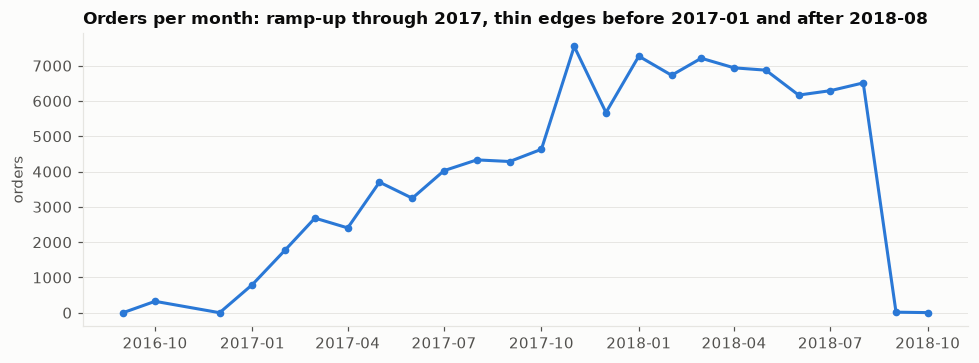

Purchase range: [Timestamp('2016-09-04 21:15:19'), Timestamp('2018-10-17 17:30:18')]


In [12]:
print("Order status mix:")
display(q("select order_status, count(*) orders, count(*) * 1.0 / sum(count(*)) over () share_of_orders from orders group by 1 order by 2 desc"))

monthly = q("""select date_trunc('month', order_purchase_timestamp) order_month, count(*) orders
               from orders group by 1 order by 1""")
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(monthly.order_month, monthly.orders, color=BLUE, lw=2, marker="o", ms=4)
ax.set_title("Orders per month: ramp-up through 2017, thin edges before 2017-01 and after 2018-08")
ax.set_ylabel("orders"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print("Purchase range:", q("select min(order_purchase_timestamp) first_order, max(order_purchase_timestamp) last_order from orders").iloc[0].tolist())

count   96,476
mean     12.50
std       9.60
min          0
25%          7
50%         10
75%         16
max        210


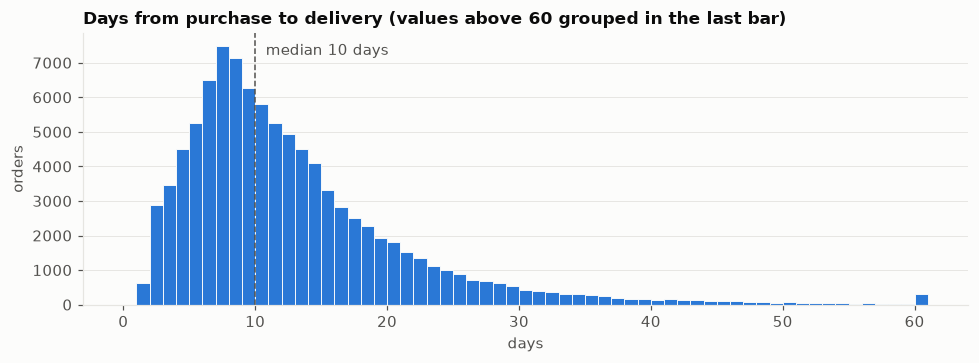

In [13]:
deliv = q("""
    select date_diff('day', order_purchase_timestamp, order_delivered_customer_date) days_to_deliver,
           date_diff('day', order_delivered_customer_date, order_estimated_delivery_date) days_early
    from orders where order_delivered_customer_date is not null""")
print(deliv.days_to_deliver.describe().round(1).to_string())
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(deliv.days_to_deliver.clip(upper=60), bins=range(0, 62), color=BLUE, edgecolor=SURFACE, linewidth=0.6)
med = deliv.days_to_deliver.median()
ax.axvline(med, color=MUTED, lw=1, ls="--")
ax.text(med + 0.8, ax.get_ylim()[1] * 0.92, f"median {med:.0f} days", color=MUTED)
ax.set_title("Days from purchase to delivery (values above 60 grouped in the last bar)")
ax.set_xlabel("days"); ax.set_ylabel("orders"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Average review score: {'late': 2.57, 'on time': 4.29} | reviews: {'late': 7701, 'on time': 88658}


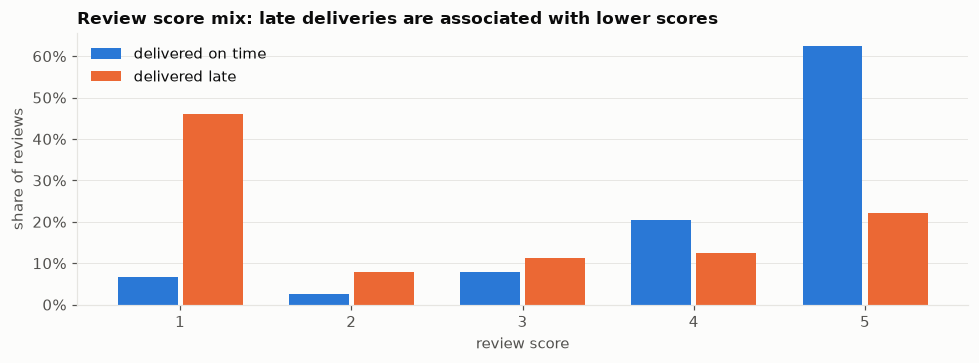

In [14]:
rv = q("""
    select r.review_score,
           case when o.order_delivered_customer_date <= o.order_estimated_delivery_date then 'on time' else 'late' end outcome,
           count(*) reviews
    from reviews r join orders o using (order_id)
    where o.order_delivered_customer_date is not null group by all""")
share = rv.pivot(index="review_score", columns="outcome", values="reviews").fillna(0)
share = share / share.sum()
avg = rv.assign(w=rv.review_score * rv.reviews).groupby("outcome").agg(w=("w", "sum"), n=("reviews", "sum"))
print("Average review score:", (avg.w / avg.n).round(2).to_dict(), "| reviews:", avg.n.to_dict())

fig, ax = plt.subplots(figsize=(9, 3.4))
x = share.index.to_numpy(); w = 0.38
ax.bar(x - w / 2, share["on time"], width=w - 0.03, color=BLUE, label="delivered on time")
ax.bar(x + w / 2, share["late"], width=w - 0.03, color=ORANGE, label="delivered late")
ax.set_title("Review score mix: late deliveries are associated with lower scores")
ax.set_xlabel("review score"); ax.set_ylabel("share of reviews"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x", visible=False); ax.legend()
plt.tight_layout(); plt.show()

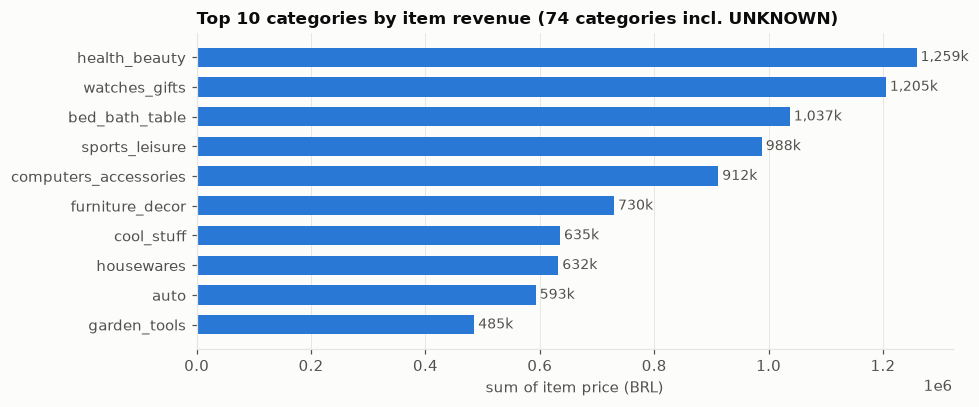

Share of revenue in top 10: 62.4%
Customers by state (top 8):


,customer_state,customers
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045
5,SC,3637
6,BA,3380
7,DF,2140


In [15]:
cat = q("""
    select coalesce(t.product_category_name_english, p.product_category_name, 'UNKNOWN') category,
           count(*) items, sum(i.price) revenue
    from items i join products p using (product_id)
    left join translation t using (product_category_name)
    group by 1 order by 3 desc""")
top = cat.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(top.category, top.revenue, color=BLUE, height=0.65)
for y, v in enumerate(top.revenue):
    ax.text(v, y, f" {v / 1e3:,.0f}k", va="center", color=MUTED, fontsize=9)
ax.set_title(f"Top 10 categories by item revenue ({len(cat)} categories incl. UNKNOWN)")
ax.set_xlabel("sum of item price (BRL)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print("Share of revenue in top 10:", f"{cat.head(10).revenue.sum() / cat.revenue.sum():.1%}")
print("Customers by state (top 8):")
display(q("select customer_state, count(*) customers from customers group by 1 order by 2 desc limit 8"))

**Finding - distributions.**
- 97% of orders are `delivered`; the rest are mostly `shipped`, `canceled` and `unavailable`.
- Volume ramps through 2017 (peak 7,544 orders in 2017-11) and is stable at roughly 6-7k per month in 2018; 2016 and the months after 2018-08 are thin, and **2016-11 has no orders** - `dim_date` must be a complete calendar, not derived from order dates.
- Delivery takes a median 10 days (mean 12.5, max 210). Late deliveries are **associated with** lower review scores (average 2.57 vs 4.29 on time; 7,701 vs 88,658 reviews).
- The top 10 categories are 62.4% of item revenue; Sao Paulo (SP) holds 41,746 of 99,441 customer ids (42%).

## 8. Geolocation
The geolocation file has ~1M rows for ~19k zip prefixes. It needs collapsing to one row per prefix before it can be a dimension.

In [16]:
display(q("""
    select count(*) points, count(distinct geolocation_zip_code_prefix) prefixes,
           sum((geolocation_lat not between -34 and 6 or geolocation_lng not between -74 and -28)::int) outside_brazil_bbox,
           (select count(*) from (select geolocation_zip_code_prefix from geo group by 1
                                  having count(distinct geolocation_state) > 1)) prefixes_in_multiple_states
    from geo"""))
con.execute("""
    create or replace view geo_by_zip as
    select geolocation_zip_code_prefix zip_prefix,
           median(geolocation_lat) lat, median(geolocation_lng) lng,
           mode(geolocation_state) state, mode(geolocation_city) city, count(*) n_points
    from geo
    where geolocation_lat between -34 and 6 and geolocation_lng between -74 and -28
    group by 1""")
display(q("select count(*) prefixes, min(n_points) min_points, median(n_points) median_points, max(n_points) max_points from geo_by_zip"))
display(q("""
    select 'customers' entity, count(*) n_rows, sum((customer_zip_code_prefix in (select zip_prefix from geo_by_zip))::int) rows_matched,
           count(distinct customer_zip_code_prefix) distinct_prefixes,
           count(distinct customer_zip_code_prefix) filter (where customer_zip_code_prefix not in (select zip_prefix from geo_by_zip)) prefixes_unmatched
    from customers
    union all
    select 'sellers', count(*), sum((seller_zip_code_prefix in (select zip_prefix from geo_by_zip))::int),
           count(distinct seller_zip_code_prefix),
           count(distinct seller_zip_code_prefix) filter (where seller_zip_code_prefix not in (select zip_prefix from geo_by_zip))
    from sellers"""))

,points,prefixes,outside_brazil_bbox,prefixes_in_multiple_states
0,1000163,19015,31,8


,prefixes,min_points,median_points,max_points
0,19011,1,29,1146


,entity,n_rows,rows_matched,distinct_prefixes,prefixes_unmatched
0,customers,99441,"99,162",14994,158
1,sellers,3095,"3,088",2246,7


**Finding - geolocation.** 31 points fall outside a Brazil bounding box and are excluded; 8 prefixes appear in more than one state, so state and city take the most common value. Collapsing to one row per prefix (median latitude/longitude) gives 19,011 prefixes. Coverage is high: 99,162 of 99,441 customer rows (99.7%; 158 distinct prefixes unmatched) and 3,088 of 3,095 sellers (7 unmatched). Unmatched rows get an "unknown" geography member rather than being dropped.

## 9. Decisions for the star schema

| # | Finding | Decision |
|---|---|---|
| 1 | Items unique on (`order_id`, `order_item_id`) and carry all revenue | `fact_order_items` is the core fact, grain = one order item |
| 2 | 775 orders have no items; status and delivery timestamps live on `orders` | `fact_orders`, grain = one order, keeps all 99,441 orders |
| 3 | Payments are multi-row per order and do not always equal items + freight | `fact_payments`, grain = (`order_id`, `payment_sequential`); revenue measured from items only |
| 4 | `review_id` is not unique; 547 orders have 2-3 reviews | `fact_reviews`, grain = (`review_id`, `order_id`); never joined directly to items |
| 5 | Joining child tables side by side overstates revenue by 4.5-5% | Facts never join to facts; use shared dimensions or pre-aggregate to a common grain |
| 6 | `customer_id` is per order; 96,096 real customers; 250 change location | `dim_customer` at `customer_unique_id` grain (city/state from the latest order); the location at the time of each order is carried on the facts through `dim_geography` |
| 7 | 610 null categories; 13 untranslated categories; misspelled columns | `dim_product` with English category (falls back to the Portuguese name, then "unknown"); columns renamed in staging |
| 8 | Delivery milestones are nullable; 2016-11 has no orders; 4 shipping limit dates fall in 2020 | Role-playing `dim_date` over a complete generated calendar (whole years, 2016-2020); null dates map to a "not applicable" member (key -1); outliers kept as recorded |
| 9 | Geolocation has ~53 points per prefix and 99.7% coverage | `dim_geography` at zip-prefix grain from median coordinates, role-played on the facts (customer and seller location); unmatched zips map to the unknown member (key -1) |
| 10 | Timestamp errors (166 + 23 orders), 8 delivered orders with no delivery date | Kept as-is; derived measures (delivery days, delay) are nullable and carry quality flags |
